In [2]:
# Монтируем Google Drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

### 1. Загрузка данных и первичный анализ признаков обьединенного набора

Загружаем `oasis_merged.parquet` в датафрейм `df_raw`, проверяем размерность, типы данных, полные дубликаты строк и убеждаемся в корректности идентификаторов субьектов.

In [4]:
# Настройка отображения таблиц и графиков в Colab
pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style="whitegrid", palette="muted")

In [6]:
# Загрузка датасета в глобальную переменную df_raw
df_raw = pd.read_parquet('/content/drive/MyDrive/mri/oasis_merged.parquet')

print("=" * 60)
print(f"ПЕРВИЧНАЯ СВОДКА ПО ДАТАСЕТУ")
print("=" * 60)
print(f"Исходная размерность (строки, колонки): {df_raw.shape}")
print(f"Полных дубликатов строк: {df_raw.duplicated().sum()}")

id_col = 'subject_id'
print(f"Колонка идентификатора субьекта: '{id_col}' (уникальных значений: {df_raw[id_col].nunique()})")

# Распределение типов данных
print("\nТипы данных в датафрейме:")
print(df_raw.dtypes.value_counts())

ПЕРВИЧНАЯ СВОДКА ПО ДАТАСЕТУ
Исходная размерность (строки, колонки): (425, 439)
Полных дубликатов строк: 0
Колонка идентификатора субьекта: 'subject_id' (уникальных значений: 425)

Типы данных в датафрейме:
float64    434
object       3
int64        2
Name: count, dtype: int64


### 2. Разделение повторных визитов

В датасете OASIS-1 20 молодых здоровых испытуемых прошли повторное сканирование (`_MR2`, где `Delay` указывает количество дней с первого сканирования `_MR1`) для оценки технической воспроизводимости томографа.

* Если оставить эти строки в основном датафрейме, один и тот же человек может попасть и в `train`, и в `test` что приведёт к утечке данных (Data Leakage).
* Мы выделяем повторные визиты в отдельный датафрейм `df_retest` Он будет использован для оценки погрешности самого FreeSurfer. В рабочем датафрейме `df_base` оставляем только первичные визиты (`_MR1`).

In [7]:
# Обработка повторных сканирований (_MR2, Delay)
# фильтр по суффиксу _MR2 в идентификаторе
retest_mask = df_raw[id_col].astype(str).str.contains('_MR2', na=False)

# Формируем основной и тестовый датафреймы
df_retest = df_raw[retest_mask].copy()
df_base = df_raw[~retest_mask].copy()

print("=" * 60)
print(f"ФИЛЬТРАЦИЯ ПОВТОРНЫХ СКАНИРОВАНИЙ")
print("=" * 60)
print(f"Выделено повторных сессий в df_retest: {len(df_retest)}")
print(f"Оставлено уникальных испытуемых в основном df_base: {len(df_base)}")

if len(df_retest) > 0 and 'Delay' in df_retest.columns:
    delay_vals = pd.to_numeric(df_retest['Delay'], errors='coerce')
    print(
      f"Интервал между сканированиями (Delay, дни): "
      f"min={delay_vals.min():.0f}, "
      f"median={delay_vals.median():.1f}, "
      f"max={delay_vals.max():.0f}"
    )

ФИЛЬТРАЦИЯ ПОВТОРНЫХ СКАНИРОВАНИЙ
Выделено повторных сессий в df_retest: 20
Оставлено уникальных испытуемых в основном df_base: 405
Интервал между сканированиями (Delay, дни): min=1, median=11.0, max=89


### 3. Проверка клинических и демографических признаков и анализ пропусков


In [8]:
# Выделение клинико-демографических колонок и аудит пропусков
clinical_expected = ['M/F', 'Hand', 'Age', 'Educ',
                     'SES', 'MMSE', 'CDR', 'eTIV',
                     'nWBV', 'ASF', 'Delay']
clinical_cols = [c for c in clinical_expected if c in df_base.columns]

print("=" * 60)
print(f"АУДИТ КЛИНИЧЕСКИХ И ДЕМОГРАФИЧЕСКИХ ПРИЗНАКОВ")
print("=" * 60)
print(f"Найдено клинических колонок ({len(clinical_cols)}): {clinical_cols}\n")

# Сводная таблица пропусков и уникальных значений по клиническим признакам
clinical_audit = pd.DataFrame({
    'Dtype': df_base[clinical_cols].dtypes,
    'Missing_Count': df_base[clinical_cols].isna().sum(),
    'Missing_Pct (%)': (df_base[clinical_cols].isna().mean() * 100).round(2),
    'Unique_Values': df_base[clinical_cols].nunique(dropna=True)
})
display(clinical_audit)

АУДИТ КЛИНИЧЕСКИХ И ДЕМОГРАФИЧЕСКИХ ПРИЗНАКОВ
Найдено клинических колонок (11): ['M/F', 'Hand', 'Age', 'Educ', 'SES', 'MMSE', 'CDR', 'eTIV', 'nWBV', 'ASF', 'Delay']



,Dtype,Missing_Count,Missing_Pct (%),Unique_Values
M/F,object,0,0.00,2
Hand,object,0,0.00,1
Age,int64,0,0.00,73
Educ,float64,179,44.20,5
SES,float64,198,48.89,5
MMSE,float64,179,44.20,16
CDR,float64,179,44.20,4
eTIV,int64,0,0.00,296
nWBV,float64,0,0.00,181
ASF,float64,0,0.00,273


In [9]:
# Проверка связи пропусков в CDR/MMSE с возрастом
age_cdr_na = df_base.loc[df_base['CDR'].isna(), 'Age']
age_cdr_valid = df_base.loc[df_base['CDR'].notna(), 'Age']

print("=" * 65)
print("Распределение возраста (Age) в зависимости от наличия CDR")
print("=" * 65)

print(
    f"Испытуемые с ПРОПУСКОМ в CDR (n={len(age_cdr_na)}): "
    f"Age min={age_cdr_na.min()}, "
    f"max={age_cdr_na.max()}, "
    f"median={age_cdr_na.median()}"
)

print(
    f"Испытуемые с ЗАПОЛНЕННЫМ CDR (n={len(age_cdr_valid)}): "
    f"Age min={age_cdr_valid.min()}, "
    f"max={age_cdr_valid.max()}, "
    f"median={age_cdr_valid.median()}"
)

Распределение возраста (Age) в зависимости от наличия CDR
Испытуемые с ПРОПУСКОМ в CDR (n=179): Age min=18, max=58, median=23.0
Испытуемые с ЗАПОЛНЕННЫМ CDR (n=226): Age min=33, max=96, median=73.0


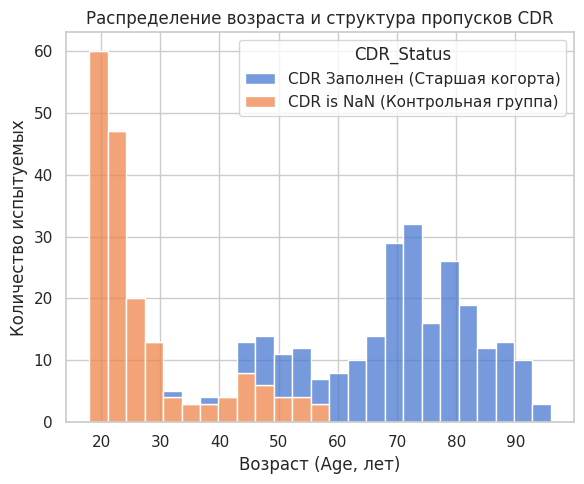

In [10]:
# Возраст при наличии/отсутствии CDR
plt.figure(figsize=(6, 5))

df_base['CDR_Status'] = np.where(
    df_base['CDR'].isna(),
    'CDR is NaN (Контрольная группа)',
    'CDR Заполнен (Старшая когорта)'
)
sns.histplot(data=df_base, x='Age', hue='CDR_Status', bins=25, multiple='stack')

plt.title('Распределение возраста и структура пропусков CDR')
plt.xlabel('Возраст (Age, лет)')
plt.ylabel('Количество испытуемых')
plt.tight_layout()
plt.show()

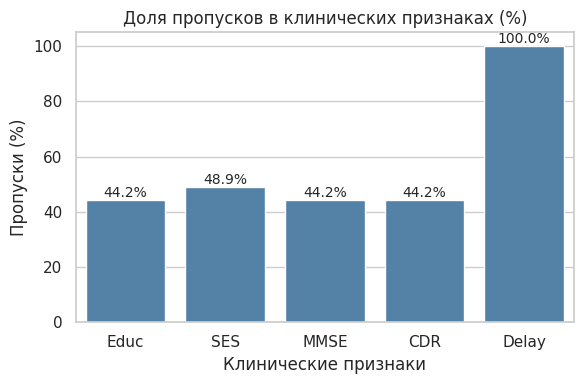

In [11]:
# Процент пропусков по клиническим признакам
missing_clin = clinical_audit[clinical_audit['Missing_Count'] > 0]

plt.figure(figsize=(6, 4))

ax = sns.barplot(x=missing_clin.index, y=missing_clin['Missing_Pct (%)'], color='steelblue')
plt.title('Доля пропусков в клинических признаках (%)')
plt.xlabel('Клинические признаки')
plt.ylabel('Пропуски (%)')

for i, v in enumerate(missing_clin['Missing_Pct (%)']):
    ax.text(i, v + 1, f"{v:.1f}%", ha='center', fontsize=10)

plt.tight_layout()
plt.show()

### 4. Чистка константных и пустых признаков FreeSurfer

При выгрузке таблиц `aseg.stats`, `lh.aparc.stats` и `rh.aparc.stats` из FreeSurfer в таблицу попадают технические колонки, часть из них мы уже отфильтровали на этапе загрузки. Кроме того, демографический признак `Hand` в OASIS-1 константен (все испытуемые — правши `'R'`).

In [12]:
# Поиск и фильтрация константных, полностью пустых и дублирующихся колонок
non_morph_cols = set(clinical_cols + ([id_col] if id_col else []))
morph_raw_cols = [c for c in df_base.columns if c not in non_morph_cols]

print("=" * 60)
print(f"АУДИТ МОРФОМЕТРИЧЕСКИХ КОЛОНОК FREESURFER")
print("=" * 60)

print(f"Размерность датафрейма до очистки df_base: {df_base.shape}")
print(f"\nВсего морфометрических колонок до очистки: {len(morph_raw_cols)}")

# Проверка пропусков внутри морфометрии FreeSurfer
morph_na_series = df_base[morph_raw_cols].isna().sum()
morph_cols_with_na = morph_na_series[morph_na_series > 0]
print(f"Морфометрических колонок с NaN: {len(morph_cols_with_na)}")
if len(morph_cols_with_na) > 0:
    print(morph_cols_with_na)
    # Дополнительно проверяем, какие строки имеют пропуски в морфометрии
    rows_with_morph_na = df_base[morph_raw_cols].isna().any(axis=1).sum()
    print(f"Строк (субъектов) с пропусками в FreeSurfer: {rows_with_morph_na}")

# Поиск признаков с нулевой дисперсией (константы или все нули)
constant_cols = []
for col in df_base.columns:
    if col == id_col or col == 'Delay':
        continue
    nunique_val = df_base[col].nunique(dropna=True)
    if nunique_val <= 1:
        constant_cols.append(col)

# Поиск признаков, где >95% значений равны нулю
quasi_zero_cols = []
for col in morph_raw_cols:
    if col not in constant_cols and pd.api.types.is_numeric_dtype(df_base[col]):
        zero_ratio = (df_base[col] == 0).mean()
        if zero_ratio > 0.95:
            quasi_zero_cols.append((col, round(zero_ratio * 100, 2)))

print(f"\nНайдено строго константных колонок ({len(constant_cols)}): {constant_cols}")
print(f"Найдено квази-нулевых морфометрических колонок (>95% нулей, {len(quasi_zero_cols)}): {quasi_zero_cols}")

# Список колонок на удаление (сохраняем в глобальную переменную drop_cols)
drop_cols = list(set(constant_cols + [c[0] for c in quasi_zero_cols] + ['Delay']))
drop_cols = [c for c in drop_cols if c in df_base.columns]

# Создаем очищенный глобальный датафрейм df_clean
# Если есть единичные субъекты с битым парсингом FreeSurfer
# (NaN в морфометрии), также отфильтруем их
valid_morph_mask = df_base[morph_raw_cols].notna().all(axis=1)
if (~valid_morph_mask).sum() > 0:
    print(
        f"\nВНИМАНИЕ: Удалено {(~valid_morph_mask).sum()} строк"
        f" с отсутствующей сегментацией FreeSurfer.")

df_clean = df_base.loc[valid_morph_mask].drop(columns=drop_cols).copy()

print(f"\nИтого удалено неинформативных/технических колонок: {len(drop_cols)} -> {drop_cols}")
print(f"Размерность очищенного датафрейма df_clean: {df_clean.shape}")

АУДИТ МОРФОМЕТРИЧЕСКИХ КОЛОНОК FREESURFER
Размерность датафрейма до очистки df_base: (405, 440)

Всего морфометрических колонок до очистки: 428
Морфометрических колонок с NaN: 0

Найдено строго константных колонок (1): ['Hand']
Найдено квази-нулевых морфометрических колонок (>95% нулей, 0): []

Итого удалено неинформативных/технических колонок: 2 -> ['Hand', 'Delay']
Размерность очищенного датафрейма df_clean: (405, 438)


### 5. Классификация морфометрических признаков по физическому смыслу

Признаки из `aseg.stats` и `aparc.stats` имеют разную природу и по-разному зависят от размера черепа (`eTIV`):

1. Региональные объемы (`aseg` и `aparc` `_GrayVol`) и площади поверхности (`_SurfArea`) масштабируются с `eTIV` (чем крупнее человек, тем больше объем гиппокампа и площадь коры), по этому эти признаки требуют обязательной нормировки на `eTIV`.
2. Толщина коры (`_ThickAvg`, `_ThickStd`) практически не зависит от размера черепа и ее не надо делить на `eTIV`.
3. Индексы кривизны и складчатости (`_MeanCurv`, `_GausCurv`, `_FoldInd`, `_CurvInd`) это геометрические характеристики.
4. Интенсивности/Воксельные счетчики (`_normMean`, `_NVoxels`, `_NumVert`) это технические метрики.

In [13]:
# Разметка пространства признаков FreeSurfer в глобальные списки
all_clean_morph = [c for c in df_clean.columns if c not in clinical_cols and c != id_col]

# Разделение по источнику (aseg vs lh.aparc vs rh.aparc)
aseg_cols = [c for c in all_clean_morph if c.startswith('aseg_')]
lh_aparc_cols = [c for c in all_clean_morph
                 if c.startswith('lh_') or c.startswith('lh.')]
rh_aparc_cols = [c for c in all_clean_morph
                 if c.startswith('rh_') or c.startswith('rh.')]

# Разделение по биофизическому типу метрики
# Глобальные и сводные объемы из aseg (BrainSegVol, ICV, CortexVol и т.д.)
global_aseg_keywords = ['BrainSeg', 'BrainMask', 'ICV',
                        'IntraCranial', 'Cortex', 'WhiteMatter',
                        'TotalGray', 'Supratentorial', 'SubCortGray']
aseg_global_cols = [c for c in aseg_cols
                    if any(k in c for k in global_aseg_keywords)]

# Региональные подкорковые объемы aseg
# (исключая технические метрики интенсивности normMean/Std/Min/Max и NVoxels)
tech_aseg_suffixes = ('_normMean', '_normStdDev',
                      '_normMin', '_normMax', '_normRange', '_NVoxels')
aseg_tech_cols = [c for c in aseg_cols if c.endswith(tech_aseg_suffixes)]
aseg_regional_vol_cols = [c for c in aseg_cols
                          if c not in aseg_global_cols and c not in aseg_tech_cols]

# Корковые метрики aparc по суффиксам FreeSurfer
aparc_all = lh_aparc_cols + rh_aparc_cols
aparc_vol_cols = [c for c in aparc_all if 'GrayVol' in c or 'Volume' in c]
aparc_area_cols = [c for c in aparc_all if 'SurfArea' in c or 'Area' in c]
aparc_thick_avg_cols = [c for c in aparc_all if 'ThickAvg' in c]
aparc_thick_std_cols = [c for c in aparc_all if 'ThickStd' in c]
aparc_curv_cols = [c for c in aparc_all
                   if any(k in c for k in ['MeanCurv', 'GausCurv',
                                           'FoldInd', 'CurvInd'])]
aparc_tech_cols = [c for c in aparc_all if 'NumVert' in c]

# Сводная таблица структуры признаков
feature_summary = pd.DataFrame([
    {'Категория признаков': 'Клинические и демографические (очищенные)',
     'Переменная в коде': 'clinical_cols',
     'Кол-во': len([c for c in clinical_cols if c in df_clean.columns]),
     'Требует нормировки на eTIV': 'Нет'},
    {'Категория признаков': 'Глобальные сводные метрики (aseg)',
     'Переменная в коде': 'aseg_global_cols',
     'Кол-во': len(aseg_global_cols),
     'Требует нормировки на eTIV': 'Частично (кроме ICV)'},
    {'Категория признаков': 'Подкорковые объемы и желудочки (aseg)',
     'Переменная в коде': 'aseg_regional_vol_cols',
     'Кол-во': len(aseg_regional_vol_cols),
     'Требует нормировки на eTIV': 'Да (Объемы)'},
    {'Категория признаков': 'Объемы серого вещества коры (aparc GrayVol)',
     'Переменная в коде': 'aparc_vol_cols',
     'Кол-во': len(aparc_vol_cols),
     'Требует нормировки на eTIV': 'Да (Объемы)'},
    {'Категория признаков': 'Площадь поверхности коры (aparc SurfArea)',
     'Переменная в коде': 'aparc_area_cols',
     'Кол-во': len(aparc_area_cols),
     'Требует нормировки на eTIV': 'Да (Площади)'},
    {'Категория признаков': 'Средняя толщина коры (aparc ThickAvg)',
     'Переменная в коде': 'aparc_thick_avg_cols',
     'Кол-во': len(aparc_thick_avg_cols),
     'Требует нормировки на eTIV': 'Нет (мм)'},
    {'Категория признаков': 'Стд. откл. толщины коры (aparc ThickStd)',
     'Переменная в коде': 'aparc_thick_std_cols',
     'Кол-во': len(aparc_thick_std_cols),
     'Требует нормировки на eTIV': 'Нет (мм)'},
    {'Категория признаков': 'Кривизна и складчатость (aparc Curv/Fold)',
     'Переменная в коде': 'aparc_curv_cols', 'Кол-во': len(aparc_curv_cols),
     'Требует нормировки на eTIV': 'Опционально'},
    {'Категория признаков': 'Технические метрики (NVoxels, NumVert, normMean)',
     'Переменная в коде': 'aseg_tech_cols + aparc_tech_cols',
     'Кол-во': len(aseg_tech_cols) + len(aparc_tech_cols),
     'Требует нормировки на eTIV': 'Исключить из ML'}
])

print("=" * 60)
print("ПРИЗНАКИ ПО ФИЗИЧЕСКОМУ СМЫСЛУ")
print("=" * 60)
display(feature_summary)

ПРИЗНАКИ ПО ФИЗИЧЕСКОМУ СМЫСЛУ


,Категория признаков,Переменная в коде,Кол-во,Требует нормировки на eTIV
0,Клинические и демографические (очищенные),clinical_cols,9,Нет
1,Глобальные сводные метрики (aseg),aseg_global_cols,11,Частично (кроме ICV)
2,Подкорковые объемы и желудочки (aseg),aseg_regional_vol_cols,41,Да (Объемы)
3,Объемы серого вещества коры (aparc GrayVol),aparc_vol_cols,66,Да (Объемы)
4,Площадь поверхности коры (aparc SurfArea),aparc_area_cols,68,Да (Площади)
5,Средняя толщина коры (aparc ThickAvg),aparc_thick_avg_cols,66,Нет (мм)
6,Стд. откл. толщины коры (aparc ThickStd),aparc_thick_std_cols,66,Нет (мм)
7,Кривизна и складчатость (aparc Curv/Fold),aparc_curv_cols,66,Опционально
8,"Технические метрики (NVoxels, NumVert, normMean)",aseg_tech_cols + aparc_tech_cols,47,Исключить из ML


### 6. Валидация глобальных признаков (`eTIV`, `aseg_ICV`, `ASF`)

1. В объединенном датасете внутричерепной объем присутствует дважды: как клиническая колонка `eTIV` (из таблицы OASIS-1 CSV) и как `aseg_ICV` (из заголовка файла `aseg.stats`). В таблице OASIS-1 `eTIV` записан в $\text{мм}^3 \times 10^{-3}$ (значения около $1100–2000$), а в `aseg.stats` объемы идут в $\text{мм}^3$ (значения около $1.1 \times 10^6 – 2.0 \times 10^6$). Это нужно проверить, чтобы не перепутать масштабы при нормировке.
2. Признак `ASF` (Atlas Scaling Factor) — это коэффициент трансформации матрицы в атлас Тейлараха, который вычисляется аналитически как $ASF = \frac{1755}{\text{eTIV}}$. Между `ASF` и `eTIV` существует обратная зависимость, поэтому одновременное включение обоих признаков в линейные модели вызовет мультиколлинеарность.

In [14]:
# Проверка согласованности глобальных признаков масштаба головы (eTIV, aseg_ICV, ASF)
print("=" * 65)
print("ПРОВЕРКА СОГЛАСОВАННОСТИ ГЛОБАЛЬНЫХ МЕТРИК (eTIV, aseg_ICV и ASF)")
print("=" * 65)

# Ищем колонку ICV из aseg
icv_candidates = [c for c in aseg_global_cols if 'ICV' in c or 'IntraCranial' in c]
aseg_icv_col = icv_candidates[0] if icv_candidates else None

if 'eTIV' in df_clean.columns and aseg_icv_col:
    r_icv, p_icv = stats.pearsonr(df_clean['eTIV'], df_clean[aseg_icv_col])
    ratio_series = df_clean[aseg_icv_col] / df_clean['eTIV']

    print(f"1. Сравнение 'eTIV' и '{aseg_icv_col}':")
    print(f"   • Диапазон eTIV: [{df_clean['eTIV'].min():.2f}, {df_clean['eTIV'].max():.2f}] (медиана: {df_clean['eTIV'].median():.2f})")
    print(f"   • Диапазон {aseg_icv_col}: [{df_clean[aseg_icv_col].min():.2f}, {df_clean[aseg_icv_col].max():.2f}] (медиана: {df_clean[aseg_icv_col].median():.2f})")
    print(f"   • Корреляция Пирсона: r = {r_icv:.6f} (p = {p_icv:.2e})")
    print(f"   • Медианное отношение ({aseg_icv_col} / eTIV): {ratio_series.median():.2f}")

    if 900 < ratio_series.median() < 1100:
        print("\n   => ВЫВОД: 'eTIV' измерен в см³, а объемы FreeSurfer - в мм³ (разница в 1000 раз).")
    elif 0.9 < ratio_series.median() < 1.1:
        print("   => ВЫВОД: Обе переменные измерены в одних и тех же единицах.")

if 'eTIV' in df_clean.columns and 'ASF' in df_clean.columns:
    r_asf, p_asf = stats.pearsonr(df_clean['eTIV'], df_clean['ASF'])
    spearman_asf, _ = stats.spearmanr(df_clean['eTIV'], df_clean['ASF'])
    print(f"\n2. Мультиколлинеарность 'eTIV' и 'ASF':")
    print(f"   • Корреляция Пирсона: r = {r_asf:.6f} (p = {p_asf:.2e})")
    print(f"   • Корреляция Спирмена: rho = {spearman_asf:.6f}")
    print("\n   => РЕШЕНИЕ: Исключить 'ASF' из признаков моделирования во избежание мультиколлинеарности.")



ПРОВЕРКА СОГЛАСОВАННОСТИ ГЛОБАЛЬНЫХ МЕТРИК (eTIV, aseg_ICV и ASF)
1. Сравнение 'eTIV' и 'aseg_ICV':
   • Диапазон eTIV: [1123.00, 1992.00] (медиана: 1475.00)
   • Диапазон aseg_ICV: [1107283.60, 2001763.54] (медиана: 1439909.96)
   • Корреляция Пирсона: r = 0.921622 (p = 9.40e-168)
   • Медианное отношение (aseg_ICV / eTIV): 988.96

   => ВЫВОД: 'eTIV' измерен в см³, а объемы FreeSurfer - в мм³ (разница в 1000 раз).

2. Мультиколлинеарность 'eTIV' и 'ASF':
   • Корреляция Пирсона: r = -0.974199 (p = 1.19e-262)
   • Корреляция Спирмена: rho = -0.987892

   => РЕШЕНИЕ: Исключить 'ASF' из признаков моделирования во избежание мультиколлинеарности.


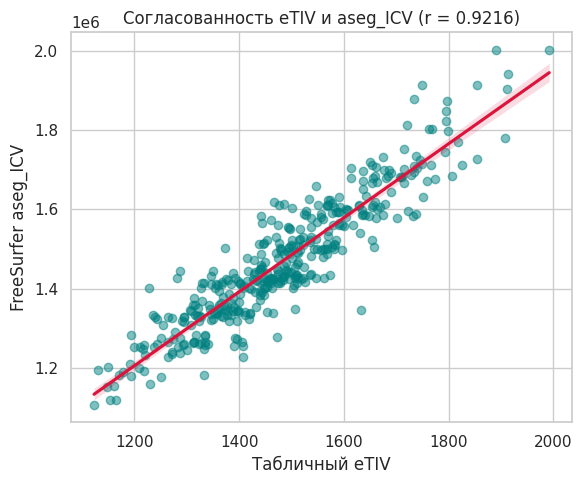

In [15]:
# Согласованность табличного eTIV и aseg_ICV из FreeSurfer
plt.figure(figsize=(6, 5))

sns.regplot(
    data=df_clean,
    x='eTIV',
    y=aseg_icv_col,
    scatter_kws={'alpha': 0.5, 'color': 'teal'},
    line_kws={'color': 'crimson'}
)
plt.title(f'Согласованность eTIV и {aseg_icv_col} (r = {r_icv:.4f})')
plt.xlabel('Табличный eTIV')
plt.ylabel(f'FreeSurfer {aseg_icv_col}')
plt.tight_layout()
plt.show()

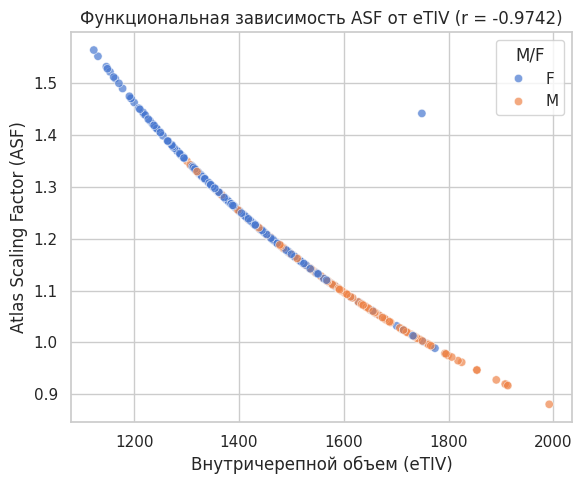

In [16]:
# Функциональная зависимость ASF от eTIV
plt.figure(figsize=(6, 5))

sns.scatterplot(
    data=df_clean,
    x='eTIV',
    y='ASF',
    hue='M/F' if 'M/F' in df_clean.columns else None,
    alpha=0.7
)
plt.title(f'Функциональная зависимость ASF от eTIV (r = {r_asf:.4f})')
plt.xlabel('Внутричерепной объем (eTIV)')
plt.ylabel('Atlas Scaling Factor (ASF)')
plt.tight_layout()
plt.show()

Результат сравнения `eTIV` и `aseg_ICV` ($r = 0.9216$, отношение $\approx 988.96$, не ровное $1.0$ и $1000$) — важная особенность устройства датасета OASIS-1. Слияние таблиц по ID прошло абсолютно верно ($p = 9.4 \times 10^{-168}$ полностью исключает сдвиг строк), но сам коэффициент $0.92$ показывает важное методологическое различие между колонкой eTIV в клиническом CSV и aseg_ICV из файлов FreeSurfer. В оригинальной статье OASIS-1 (Marcus et al., 2007, Journal of Cognitive Neuroscience) и приложенной таблице oasis_cross-sectional.csv колонки eTIV, ASF и nWBV рассчитывались НЕ в FreeSurfer.

### 7. Анализ распределения возраста (`Age`) и бимодальности выборки

В датасете OASIS-1 возраст распределен неравномерно: присутствует большой кластер молодых студентов-добровольцев (18–30 лет) и большой кластер пожилых испытуемых (60–96 лет), тогда как средний возраст (30–59 лет) представлен слабо.

In [17]:
# Статистический и визуальный анализ целевой переменной Age (для задачи Brain Age)
print("=" * 60)
print("АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ ВОЗРАСТ (Age)")
print("=" * 60)

age_series = df_clean['Age']
shapiro_stat, shapiro_p = stats.shapiro(age_series)

print(f"Всего испытуемых в df_clean: {len(age_series)}")
print(f"Диапазон возраста: от {age_series.min()} до {age_series.max()} лет")
print(f"Среднее ± SD: {age_series.mean():.2f} ± {age_series.std():.2f} лет")
print(f"Медиана (IQR): {age_series.median():.1f} ({age_series.quantile(0.25):.1f} – {age_series.quantile(0.75):.1f}) лет")
print(f"Коэффициент асимметрии (Skewness): {age_series.skew():.3f}")
print(f"Коэффициент эксцесса (Kurtosis): {age_series.kurt():.3f} (отрицательный эксцесс указывает на двугорбость)")
print(f"Тест Шапиро-Уилка на нормальность: W = {shapiro_stat:.4f}, p = {shapiro_p:.2e}\n")

АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ ВОЗРАСТ (Age)
Всего испытуемых в df_clean: 405
Диапазон возраста: от 18 до 96 лет
Среднее ± SD: 52.26 ± 24.99 лет
Медиана (IQR): 55.0 (24.0 – 74.0) лет
Коэффициент асимметрии (Skewness): -0.062
Коэффициент эксцесса (Kurtosis): -1.559 (отрицательный эксцесс указывает на двугорбость)
Тест Шапиро-Уилка на нормальность: W = 0.8845, p = 7.09e-17



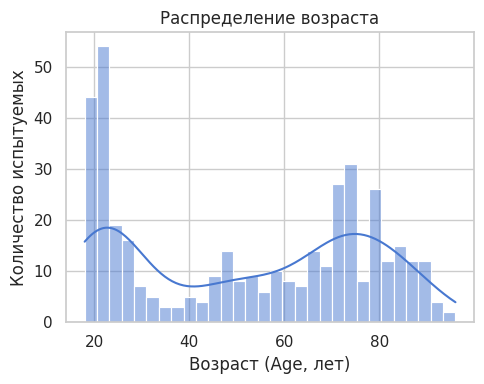

In [18]:
# Распределение возраста
plt.figure(figsize=(5, 4))

sns.histplot(data=df_base, x='Age', kde=True, bins=30, multiple='stack')

plt.title('Распределение возраста')
plt.xlabel('Возраст (Age, лет)')
plt.ylabel('Количество испытуемых')
plt.tight_layout()
plt.show()

In [19]:
# Формирование возрастных декад/групп для стратификации и анализа плотности
age_bins = [17, 29, 44, 59, 69, 79, 100]
age_labels = ['18-29', '30-44', '45-59', '60-69', '70-79', '80+']
df_clean['Age_Group'] = pd.cut(df_clean['Age'], bins=age_bins, labels=age_labels)

# Сводная таблица по возрастным стратам и полу
age_sex_table = pd.crosstab(df_clean['Age_Group'], df_clean['M/F'], margins=True, margins_name='Всего')
age_sex_table['Доля от выборки (%)'] = (age_sex_table['Всего'] / len(df_clean) * 100).round(1)

print("=" * 60)
print("Распределение испытуемых по возрастным группам и полу (M/F)")
print("=" * 60)
display(age_sex_table)

Распределение испытуемых по возрастным группам и полу (M/F)


M/F,F,M,Всего,Доля от выборки (%)
Age_Group,,,,
18-29,76,60,136,33.60
30-44,12,14,26,6.40
45-59,36,18,54,13.30
60-69,27,13,40,9.90
70-79,51,28,79,19.50
80+,48,22,70,17.30
Всего,250,155,405,100.00


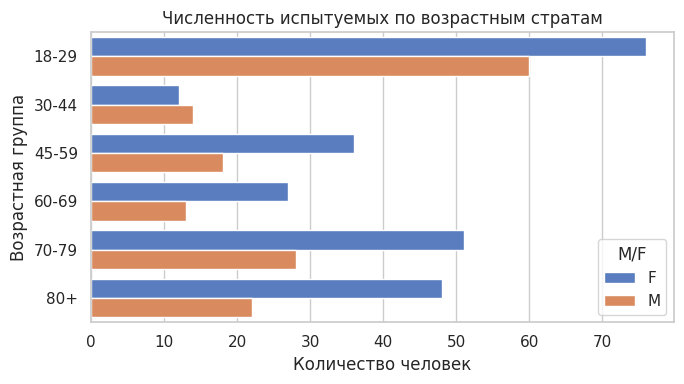

In [20]:
# Наполненность возрастных корзин
plt.figure(figsize=(7, 4))
sns.countplot(data=df_clean, y='Age_Group', hue='M/F')
plt.title('Численность испытуемых по возрастным стратам')
plt.xlabel('Количество человек')
plt.ylabel('Возрастная группа')
plt.tight_layout()
plt.show()

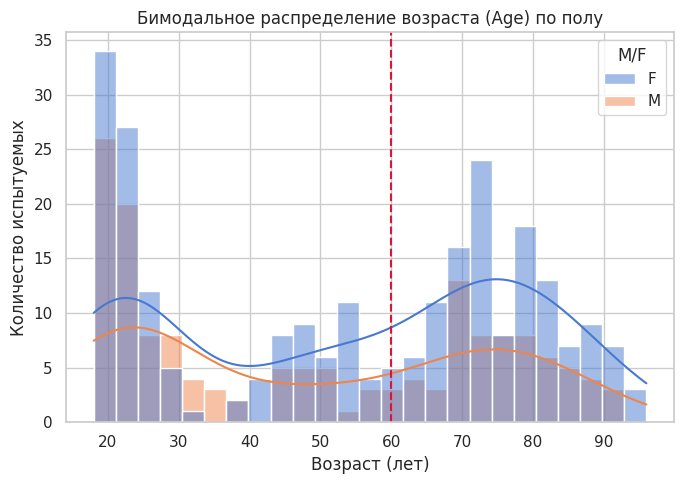

In [21]:
# Визуализация бимодальности возраста в разрезе пола

plt.figure(figsize=(7, 5))
sns.histplot(data=df_clean, x='Age', hue='M/F', bins=25, kde=True, multiple='layer', alpha=0.5)
plt.axvline(60, color='crimson', linestyle='--', linewidth=1.5, label='Граница 60 лет (когорта CDR)')
plt.title('Бимодальное распределение возраста (Age) по полу')
plt.xlabel('Возраст (лет)')
plt.ylabel('Количество испытуемых')
plt.tight_layout()
plt.show()

### 8. Анализ целевой переменной `CDR` и баланса классов деменции

Шкала `CDR` (Clinical Dementia Rating) принимает дискретные значения:

* `0.0` — когнитивная норма (отсутствие деменции);
* `0.5` — очень легкая деменция (часто соответствует стадии мягкого когнитивного снижения — MCI / ранняя болезнь Альцгеймера);
* `1.0` — легкая деменция;
* `2.0` — умеренная деменция.

В OASIS-1 класс `CDR = 2.0` представлен единичными случаями (2 человека). Обучать мультиклассовый классификатор на 4 класса при таком экстремальном дисбалансе нельзя — класс `2.0` не поделится даже на 5 фолдов кросс-валидации. Поэтому создадим два глобальных варианта таргета:

1. Бинарный (`CDR_Binary`): `0` (Норма, `CDR == 0`) против `1` (Когнитивное снижение, `CDR > 0`).
2. Трехклассовый (`CDR_3Class`): `0.0` (Норма), `0.5` (Очень легкая / MCI), `1.0+` (Клиническая деменция, объединяющая `1.0` и `2.0`).

In [22]:
# Анализ целевой переменной CDR и конструирование клинических таргетов
print("=" * 60)
print("АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ: CDR (Clinical Dementia Rating)")
print("=" * 60)

# Подсчет исходных значений CDR (включая пропуски NaN у молодых)
cdr_counts = (df_clean['CDR']
    .value_counts(dropna=False)
    .rename_axis('CDR_Raw')
    .reset_index(name='Count'))

cdr_counts['Percentage (%)'] = (cdr_counts['Count'] / len(df_clean) * 100).round(2)
display(cdr_counts)

АНАЛИЗ ЦЕЛЕВОЙ ПЕРЕМЕННОЙ: CDR (Clinical Dementia Rating)


,CDR_Raw,Count,Percentage (%)
0,NaN,179,44.20
1,0.00,133,32.84
2,0.50,68,16.79
3,1.00,23,5.68
4,2.00,2,0.49


In [23]:
# Создание очищенного статуса CDR с учетом клинического дизайна OASIS-1:
# Молодые испытуемые (Age < 60) с CDR == NaN являются здоровыми контролями
# (присваиваем 0.0 в отдельном поле CDR_Imputed)
df_clean['CDR_Imputed'] = df_clean['CDR'].copy()
young_healthy_mask = df_clean['CDR'].isna() & (df_clean['Age'] < 60)
df_clean.loc[young_healthy_mask, 'CDR_Imputed'] = 0.0

print(f"Импутировано CDR = 0.0 для молодых здоровых добровольцев (Age < 60): {young_healthy_mask.sum()} чел.")
print(f"Осталось пропусков в CDR_Imputed: {df_clean['CDR_Imputed'].isna().sum()} чел.\n")

Импутировано CDR = 0.0 для молодых здоровых добровольцев (Age < 60): 179 чел.
Осталось пропусков в CDR_Imputed: 0 чел.



In [24]:
# Формирование рабочих целевых переменных для классификации (только там, где CDR_Imputed известен)
# Бинарный таргет: 0 - Здоровые (CDR == 0), 1 - Патология (CDR >= 0.5)
df_clean['Target_CDR_Binary'] = np.where(df_clean['CDR_Imputed'] > 0, 1, 0)

# Трехклассовый порядковый таргет: объединяем редкий класс 2.0 с классом 1.0
df_clean['Target_CDR_3Class'] = df_clean['CDR_Imputed'].replace({2.0: 1.0})

In [25]:
# Статистика по когорте с изначально измеренным CDR (старшая возрастная группа)
df_measured_cdr = df_clean[df_clean['CDR'].notna()].copy()

print("=" * 60)
print("БАЛАНС КЛАССОВ В КЛИНИЧЕСКОЙ КОГОРТЕ (ГДЕ CDR ИЗМЕРЕН ЯВНО)")
print("=" * 60)

cdr_clin_table = pd.crosstab(df_measured_cdr['CDR'], df_measured_cdr['M/F'], margins=True, margins_name='Всего')
cdr_clin_table['Доля (%)'] = (cdr_clin_table['Всего'] / len(df_measured_cdr) * 100).round(2)
display(cdr_clin_table)

БАЛАНС КЛАССОВ В КЛИНИЧЕСКОЙ КОГОРТЕ (ГДЕ CDR ИЗМЕРЕН ЯВНО)


M/F,F,M,Всего,Доля (%)
CDR,,,,
0.00,97,36,133,58.85
0.50,37,31,68,30.09
1.00,16,7,23,10.18
2.00,1,1,2,0.88
Всего,151,75,226,100.00


### 9. Совместный анализ `CDR`, `MMSE`, возраста и образования

1. Валидация разметки через `MMSE` (Mini-Mental State Examination): Шкала `MMSE` (от 0 до 30 баллов) оценивает когнитивные функции независимо от `CDR`. При `CDR = 0` балл `MMSE` должен быть близок к 29–30. Если у субъекта с `CDR = 0` низкий `MMSE` (например, $< 24$), это потенциальная аномалия разметки.
2. Возрастной сдвиг между классами `CDR`: Пациенты с деменцией (`CDR > 0`) в среднем старше здоровых пожилых людей (`CDR == 0`). Если этот сдвиг статистически значим, классификатор деменции может выучить обычное нормальное старение вместо специфической болезни Альцгеймера.
3. Когнитивный резерв (`Educ`, `SES`): Уровень образования и социально-экономический статус влияют на результаты когнитивных тестов и должны проверяться на смещение между классами.

In [26]:
# Кросс-проверка CDR против MMSE, Age, Educ и глобального объема мозга (nWBV)

print("=" * 65)
print("СРАВНЕНИЕ КЛИНИЧЕСКИХ ПОКАЗАТЕЛЕЙ ПО ГРУППАМ CDR (КОГОРТА 60+)")
print("=" * 65)

# Группируем по исходному CDR (для наглядности показываем все градации 0.0, 0.5, 1.0, 2.0)
summary_cols = [c for c in ['Age', 'MMSE', 'Educ', 'SES', 'nWBV', 'eTIV'] if c in df_measured_cdr.columns]
cdr_profile = df_measured_cdr.groupby('CDR')[summary_cols].agg(['count', 'mean', 'std', 'median'])
display(cdr_profile)

# Непараметрический тест Краскела-Уоллиса на различия между группами CDR
print("\nСтатистическая значимость различий между классами CDR (тест Краскела-Уоллиса):")
for col in summary_cols:
    groups = [group[col].dropna().values for _, group in df_measured_cdr.groupby('CDR')]
    stat_kw, p_kw = stats.kruskal(*groups)
    print(f"  • {col:<6}: H = {stat_kw:7.3f}, p = {p_kw:.3e} {'(ЗНАЧИМО)' if p_kw < 0.05 else '(не значимо)'}")

# Поиск пограничных аномалий (например, CDR == 0 при MMSE <= 25)
if 'MMSE' in df_measured_cdr.columns:
    discordant_cases = df_measured_cdr[(df_measured_cdr['CDR'] == 0) & (df_measured_cdr['MMSE'] <= 25)]
    print(f"\nПограничные случаи (CDR == 0, но MMSE <= 25): найдено {len(discordant_cases)} чел.")
    if len(discordant_cases) > 0:
        cols_to_show = ([id_col] if id_col else []) + ['Age', 'M/F', 'CDR', 'MMSE', 'Educ', 'nWBV']
        display(discordant_cases[[c for c in cols_to_show if c in discordant_cases.columns]])


СРАВНЕНИЕ КЛИНИЧЕСКИХ ПОКАЗАТЕЛЕЙ ПО ГРУППАМ CDR (КОГОРТА 60+)


Age                     MMSE                    Educ                   \
     count  mean   std median count  mean  std median count mean  std median   
CDR                                                                            
0.00   133 68.83 13.84  71.00   133 29.13 1.10  29.00   133 3.44 1.27   4.00   
0.50    68 76.15  7.27  75.50    68 25.57 3.51  27.00    68 2.91 1.28   3.00   
1.00    23 77.74  7.51  78.00    23 22.13 3.85  22.00    23 2.48 1.27   2.00   
2.00     2 82.00  5.66  82.00     2 15.00 0.00  15.00     2 2.00 1.41   2.00   

       SES                   nWBV                   eTIV                 \
     count mean  std median count mean  std median count    mean    std   
CDR                                                                       
0.00   131 2.33 1.06   2.00   133 0.77 0.05   0.78   133 1440.77 153.38   
0.50    55 2.69 1.14   3.00    68 0.73 0.04   0.73    68 1491.94 184.66   
1.00    19 3.00 1.25   3.00    23 0.70 0.03   0.70    23 1468.74 102.25   
2.00     2 3.50 0.71   3.50     2 0.68 0.03   0.68     2 1456.50  78.49   

              
      median  
CDR           
0.00 1402.00  
0.50 1462.00  
1.00 1489.00  
2.00 1456.50


Статистическая значимость различий между классами CDR (тест Краскела-Уоллиса):
  • Age   : H =  18.875, p = 2.901e-04 (ЗНАЧИМО)
  • MMSE  : H = 111.635, p = 4.880e-24 (ЗНАЧИМО)
  • Educ  : H =  16.419, p = 9.303e-04 (ЗНАЧИМО)
  • SES   : H =   9.792, p = 2.042e-02 (ЗНАЧИМО)
  • nWBV  : H =  62.936, p = 1.386e-13 (ЗНАЧИМО)
  • eTIV  : H =   4.399, p = 2.214e-01 (не значимо)

Пограничные случаи (CDR == 0, но MMSE <= 25): найдено 1 чел.


,subject_id,Age,M/F,CDR,MMSE,Educ,nWBV
61,OAS1_0065_MR1,90,M,0.00,25.00,2.00,0.65


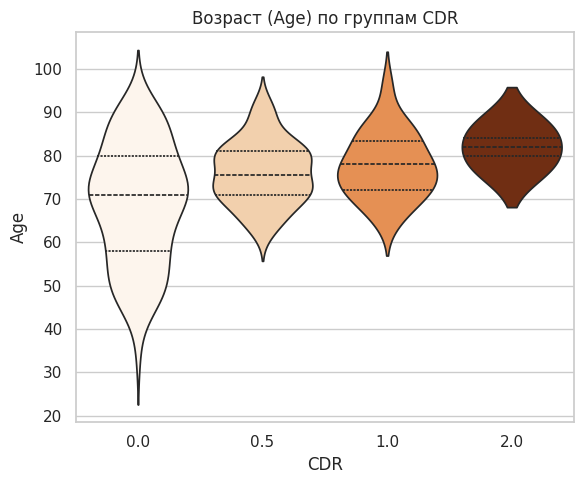

In [27]:
# Визуализация распределений MMSE, Age и nWBV по стадиям CDR

# Возраст (Age) по группам CDR
plt.figure(figsize=(6, 5))
sns.violinplot(data=df_measured_cdr, x='CDR', y='Age', palette='Oranges', inner='quartile', hue='CDR', legend=False)
plt.title('Возраст (Age) по группам CDR')
plt.tight_layout()
plt.show()

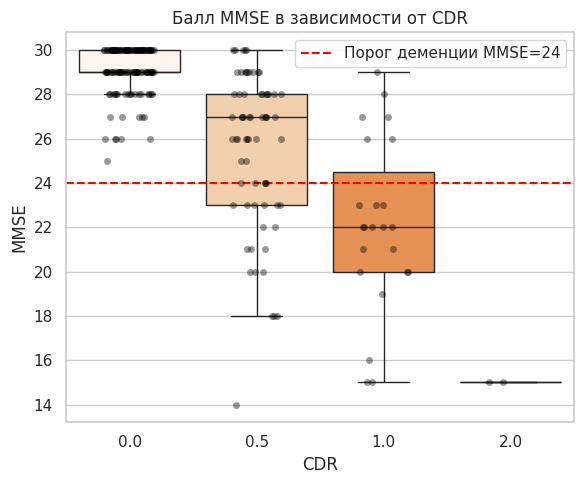

In [28]:
# Балл MMSE в зависимости от CDR
plt.figure(figsize=(6, 5))
sns.boxplot(data=df_measured_cdr, x='CDR', y='MMSE', palette='Oranges', showfliers=False, hue='CDR', legend=False)
sns.stripplot(data=df_measured_cdr, x='CDR', y='MMSE', color='black', alpha=0.4, jitter=0.2)
plt.axhline(24, color='red', linestyle='--', label='Порог деменции MMSE=24')
plt.title('Балл MMSE в зависимости от CDR')
plt.legend()
plt.tight_layout()
plt.show()

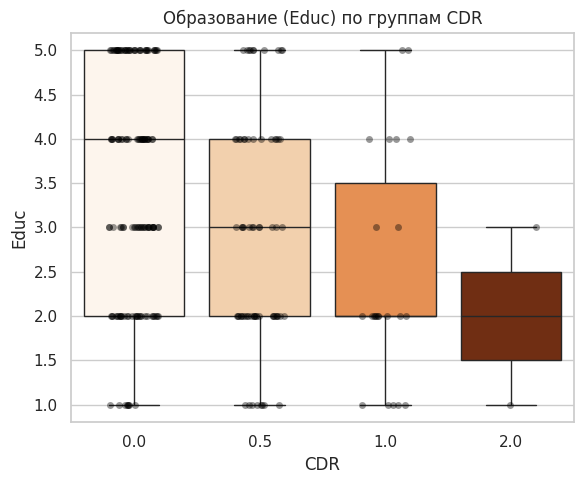

In [29]:
# Образование (Educ) по группам CDR
plt.figure(figsize=(6, 5))
sns.boxplot(data=df_measured_cdr, x='CDR', y='Educ', palette='Oranges', hue='CDR', legend=False)
sns.stripplot(data=df_measured_cdr, x='CDR', y='Educ', color='black', alpha=0.4, jitter=0.2)
plt.title('Образование (Educ) по группам CDR')
plt.tight_layout()
plt.show()

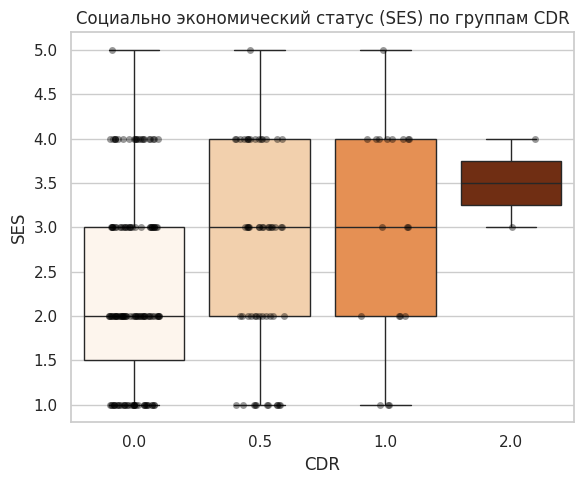

In [30]:
# Социально экономический статус (SES) по группам CDR
plt.figure(figsize=(6, 5))
sns.boxplot(data=df_measured_cdr, x='CDR', y='SES', palette='Oranges', hue='CDR', legend=False)
sns.stripplot(data=df_measured_cdr, x='CDR', y='SES', color='black', alpha=0.4, jitter=0.2)
plt.title('Социально экономический статус (SES) по группам CDR')
plt.tight_layout()
plt.show()

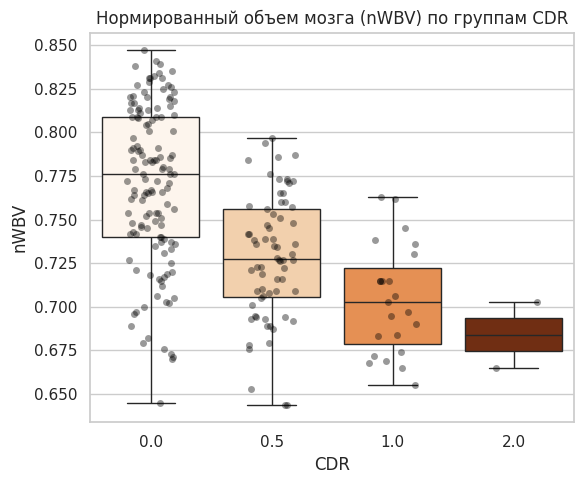

In [31]:
# Нормированный объем мозга (nWBV) по группам CDR
plt.figure(figsize=(6, 5))
sns.boxplot(data=df_measured_cdr, x='CDR', y='nWBV', palette='Oranges', hue='CDR', legend=False)
sns.stripplot(data=df_measured_cdr, x='CDR', y='nWBV', color='black', alpha=0.4, jitter=0.2)
plt.title('Нормированный объем мозга (nWBV) по группам CDR')
plt.tight_layout()
plt.show()

### 10. Формирование глобальных когорт для двух задач проекта

Мы не можем подавать один и тот же датафрейм в две разные по своей сути модели:

1. Brain Age Gap (BAG):
  * Модель оценки биологического возраста обучается и валидируется исключительно на когнитивно здоровых людях (`CDR_Imputed == 0.0`, от 18 до 96 лет). Она учится предсказывать хронологический возраст по нормальной возрастной траектории мозга.
  * Затем обученная модель применяется к тестовым здоровым субъектам и к пациентам с деменцией (`CDR > 0`). Разница $\text{Brain Age Gap (BAG)} = \widehat{\text{Age}}_{\text{predicted}} - \text{Age}_{\text{chronological}}$ показывает, насколько лет мозг пациента выглядит старше своей возрастной нормы из-за атрофии.


2. Классификация `CDR`:
  * Если включить в задачу классификации деменции людей (18–59 лет, у которых у всех `CDR = 0`), алгоритм мгновенно выучит простое правило: *если мозг молодой — деменции нет*.
  * Поэтому классификация `CDR` должна проводиться строго на возрастно-согласованной когорте старшего возраста (`Age >= 60`, где есть как здоровые пожилые `CDR == 0`, так и пациенты с `CDR > 0`).

In [33]:
# Разделение df_clean на целевые аналитические когорты

# КОГОРТА 1: Здоровый контроль во всем возрастном диапазоне (18-96 лет)
# -> для обучения модели Brain Age
df_healthy_brain_age = df_clean[df_clean['CDR_Imputed'] == 0.0].copy()

# КОГОРТА 1_EVAL: Пациенты с когнитивными нарушениями (CDR > 0)
# -> для тестирования Brain Age Gap (ускоренного старения)
df_clinical_brain_gap = df_clean[df_clean['CDR_Imputed'] > 0.0].copy()

# КОГОРТА 2: Возрастно-согласованная когорта (Age >= 60 и известный CDR)
# -> для классификации деменции
df_cdr_cohort = df_clean[(df_clean['CDR'].notna()) & (df_clean['Age'] >= 60)].copy()

# Создание комбинированного ключа стратификации для кросс-валидации в обеих задачах
# Для Brain Age: стратификация по возрастной группе и полу
df_healthy_brain_age['Strat_Key_BrainAge'] = (
    df_healthy_brain_age['Age_Group'].astype(str) + "_" + df_healthy_brain_age['M/F'].astype(str)
)

# Для классификации CDR: стратификация по бинарному CDR,
# полу и возрастному порогу (до 75 / 75+ лет)
age_split_cdr = np.where(df_cdr_cohort['Age'] >= 75, '75plus', '60to74')
df_cdr_cohort['Strat_Key_CDR'] = (
    "CDR" + df_cdr_cohort['Target_CDR_Binary'].astype(str) + "_" +
    df_cdr_cohort['M/F'].astype(str) + "_" + age_split_cdr
)

# Итоговая сводка по сформированным когортам
cohort_summary = pd.DataFrame([
    {
        'Глобальный датафрейм': 'df_clean',
        'Назначение': 'Полная очищенная выборка (все уникальные субъекты)',
        'Кол-во (N)': len(df_clean),
        'Возраст (min-max)': f"{df_clean['Age'].min()}–{df_clean['Age'].max()}",
        'Доля женщин (F, %)': round((df_clean['M/F'] == 'F').mean() * 100, 1)
    },
    {
        'Глобальный датафрейм': 'df_healthy_brain_age',
        'Назначение': 'Обучение и регрессии Brain Age (только норма CDR=0)',
        'Кол-во (N)': len(df_healthy_brain_age),
        'Возраст (min-max)': f"{df_healthy_brain_age['Age'].min()}–{df_healthy_brain_age['Age'].max()}",
        'Доля женщин (F, %)': round((df_healthy_brain_age['M/F'] == 'F').mean() * 100, 1)
    },
    {
        'Глобальный датафрейм': 'df_clinical_brain_gap',
        'Назначение': 'Оценка индекса Brain Age Gap (BAG) на пациентах с деменцией (CDR>0)',
        'Кол-во (N)': len(df_clinical_brain_gap),
        'Возраст (min-max)': f"{df_clinical_brain_gap['Age'].min()}–{df_clinical_brain_gap['Age'].max()}",
        'Доля женщин (F, %)': round((df_clinical_brain_gap['M/F'] == 'F').mean() * 100, 1)
    },
    {
        'Глобальный датафрейм': 'df_cdr_cohort',
        'Назначение': 'Обучение и классификация деменции (когорта 60+ лет)',
        'Кол-во (N)': len(df_cdr_cohort),
        'Возраст (min-max)': f"{df_cdr_cohort['Age'].min()}–{df_cdr_cohort['Age'].max()}",
        'Доля женщин (F, %)': round((df_cdr_cohort['M/F'] == 'F').mean() * 100, 1)
    }
])

print("=" * 60)
print("ИТОГОВЫЙ СОСТАВ КОГОРТ ПРОЕКТА")
print("=" * 60)
display(cohort_summary)

print("\nРаспределение стратификационных корзин для классификации деменции (Strat_Key_CDR):")
print(df_cdr_cohort['Strat_Key_CDR'].value_counts())

ИТОГОВЫЙ СОСТАВ КОГОРТ ПРОЕКТА


,Глобальный датафрейм,Назначение,Кол-во (N),Возраст (min-max),"Доля женщин (F, %)"
0,df_clean,Полная очищенная выборка (все уникальные субъе...,405,18–96,61.70
1,df_healthy_brain_age,Обучение и регрессии Brain Age (только норма C...,312,18–94,62.80
2,df_clinical_brain_gap,Оценка индекса Brain Age Gap (BAG) на пациента...,93,62–96,58.10
3,df_cdr_cohort,Обучение и классификация деменции (когорта 60+...,189,60–96,66.70



Распределение стратификационных корзин для классификации деменции (Strat_Key_CDR):
Strat_Key_CDR
CDR0_F_60to74    37
CDR0_F_75plus    35
CDR1_F_75plus    30
CDR1_F_60to74    24
CDR1_M_75plus    24
CDR1_M_60to74    15
CDR0_M_60to74    14
CDR0_M_75plus    10
Name: count, dtype: int64


### 11. Статистическая проверка конфаундеров (`M/F`, `Age`, `eTIV`)

В морфометрии мозга внутричерепной объем (`eTIV`) является главным техническим и анатомическим конфаундером (смешивающим фактором):

1. Связь `M/F` и `eTIV`  
Мужчины анатомически крупнее женщин, поэтому их средний `eTIV` статистически значимо выше (обычно на 12–15%). Если подать сырые объемы (`_Volume_mm3`, `_GrayVol`) в модель без нормировки, любой классификатор или регрессор будет путать пол человека со степенью атрофии мозга (у здоровой женщины объем гиппокампа в $\text{мм}^3$ может быть меньше, чем у мужчины с начальной стадией деменции).
2. Связь `Age` и `eTIV`  
У взрослого человека (>18 лет) размер черепа не меняется с возрастом, в отличие от паренхимы мозга (`nWBV`), которая сжимается. Однако в кросс-секционных выборке (OASIS-1) может возникать слабая корреляция `Age` и `eTIV` из-за того что молодые немного выше ростом или разной доли женщин в старшей когорте. Эту связь необходимо измерить до нормировки.

In [34]:
print("=" * 60)
print("АНАЛИЗ ВЗАИМОСВЯЗИ КОНФАУНДЕРОВ (M/F, Age, eTIV)")
print("=" * 60)

# Сравнение eTIV между мужчинами (M) и женщинами (F) в df_clean
etiv_m = df_clean.loc[df_clean['M/F'] == 'M', 'eTIV']
etiv_f = df_clean.loc[df_clean['M/F'] == 'F', 'eTIV']

t_stat, p_val_sex = stats.ttest_ind(etiv_m, etiv_f, equal_var=False)
u_stat, p_val_u = stats.mannwhitneyu(etiv_m, etiv_f)

# Размер эффекта (Cohen's d) для разницы eTIV между полами
pooled_sd = np.sqrt(((len(etiv_m) - 1) * etiv_m.var() + (len(etiv_f) - 1) * etiv_f.var()) / (len(etiv_m) + len(etiv_f) - 2))
cohens_d_sex = (etiv_m.mean() - etiv_f.mean()) / pooled_sd

print(f"1. Различия eTIV по полу (M vs F):")
print(f"   • Мужчины (M, n={len(etiv_m)}): Mean = {etiv_m.mean():.1f}, SD = {etiv_m.std():.1f}, Median = {etiv_m.median():.1f}")
print(f"   • Женщины (F, n={len(etiv_f)}): Mean = {etiv_f.mean():.1f}, SD = {etiv_f.std():.1f}, Median = {etiv_f.median():.1f}")
print(f"   • Разница средних: +{(etiv_m.mean() / etiv_f.mean() - 1) * 100:.1f}% у мужчин")
print(f"   • t-тест Уэлча: t = {t_stat:.3f}, p = {p_val_sex:.3e} | Cohen's d = {cohens_d_sex:.3f} (очень сильный эффект)\n")

# 2. Проверка связи eTIV с возрастом (Age) в целом и внутри каждого пола
r_age_all, p_age_all = stats.pearsonr(df_clean['Age'], df_clean['eTIV'])
r_age_m, p_age_m = stats.pearsonr(df_clean.loc[df_clean['M/F'] == 'M', 'Age'], etiv_m)
r_age_f, p_age_f = stats.pearsonr(df_clean.loc[df_clean['M/F'] == 'F', 'Age'], etiv_f)

print(f"2. Проверка когортного сдвига (корреляция Age и eTIV):")
print(f"   • Вся выборка: r = {r_age_all:.4f} (p = {p_age_all:.3e})")
print(f"   • Внутри мужчин (M): r = {r_age_m:.4f} (p = {p_age_m:.3e})")
print(f"   • Внутри женщин (F): r = {r_age_f:.4f} (p = {p_age_f:.3e})")

# 3. Проверка связи eTIV со статусом деменции (CDR) в когорте 60+ лет
etiv_cdr0 = df_cdr_cohort.loc[df_cdr_cohort['Target_CDR_Binary'] == 0, 'eTIV']
etiv_cdr1 = df_cdr_cohort.loc[df_cdr_cohort['Target_CDR_Binary'] == 1, 'eTIV']
t_cdr, p_cdr = stats.ttest_ind(etiv_cdr0, etiv_cdr1, equal_var=False)
print(f"\n3. Проверка независимости eTIV от деменции (когорта 60+ лет, CDR=0 vs CDR>0):")
print(f"   • t = {t_cdr:.3f}, p = {p_cdr:.4f} -> {'Нет значимого сдвига' if p_cdr > 0.05 else 'ВНИМАНИЕ: есть сдвиг по eTIV между классами!'}")

АНАЛИЗ ВЗАИМОСВЯЗИ КОНФАУНДЕРОВ (M/F, Age, eTIV)
1. Различия eTIV по полу (M vs F):
   • Мужчины (M, n=155): Mean = 1592.8, SD = 136.5, Median = 1582.0
   • Женщины (F, n=250): Mean = 1410.8, SD = 128.0, Median = 1406.0
   • Разница средних: +12.9% у мужчин
   • t-тест Уэлча: t = 13.355, p = 1.854e-32 | Cohen's d = 1.386 (очень сильный эффект)

2. Проверка когортного сдвига (корреляция Age и eTIV):
   • Вся выборка: r = -0.1379 (p = 5.450e-03)
   • Внутри мужчин (M): r = -0.0404 (p = 6.181e-01)
   • Внутри женщин (F): r = -0.1255 (p = 4.750e-02)

3. Проверка независимости eTIV от деменции (когорта 60+ лет, CDR=0 vs CDR>0):
   • t = -2.062, p = 0.0406 -> ВНИМАНИЕ: есть сдвиг по eTIV между классами!


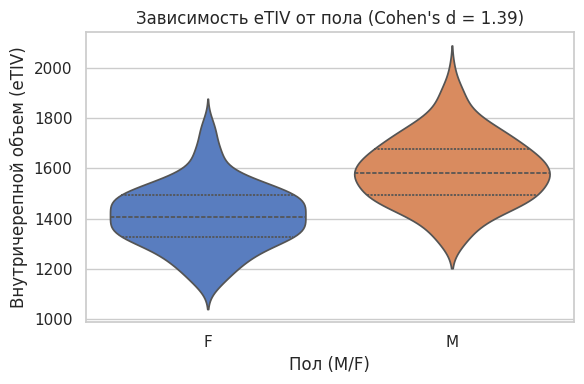

In [35]:
# Визуализация структуры конфаундеров

# Распределение eTIV по полу
plt.figure(figsize=(6, 4))
sns.violinplot(data=df_clean, x='M/F', y='eTIV', hue='M/F', inner='quartile')
plt.title(f"Зависимость eTIV от пола (Cohen's d = {cohens_d_sex:.2f})")
plt.xlabel('Пол (M/F)')
plt.ylabel('Внутричерепной объем (eTIV)')
plt.tight_layout()
plt.show()

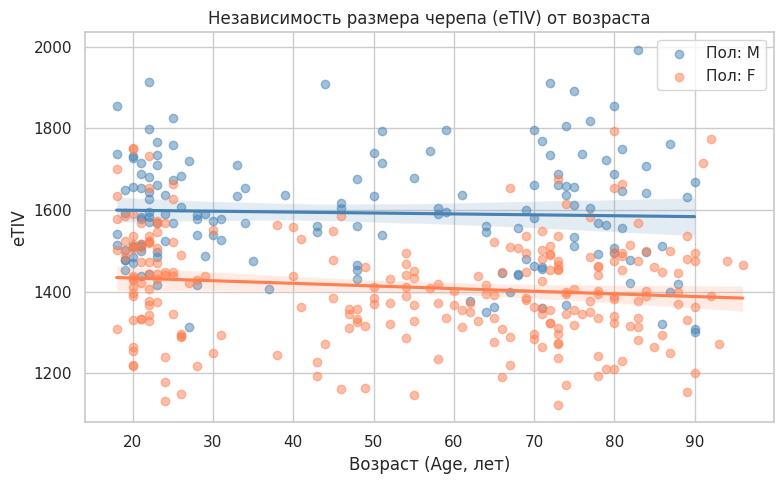

In [36]:
# Регрессия eTIV на Age по полу
plt.figure(figsize=(8, 5))
for sex_val, color in [('M', 'steelblue'), ('F', 'coral')]:
    sub = df_clean[df_clean['M/F'] == sex_val]
    sns.regplot(data=sub, x='Age', y='eTIV', label=f"Пол: {sex_val}", color=color,
                scatter_kws={'alpha': 0.5})
plt.title('Независимость размера черепа (eTIV) от возраста')
plt.xlabel('Возраст (Age, лет)')
plt.ylabel('eTIV')
plt.legend()
plt.tight_layout()
plt.show()

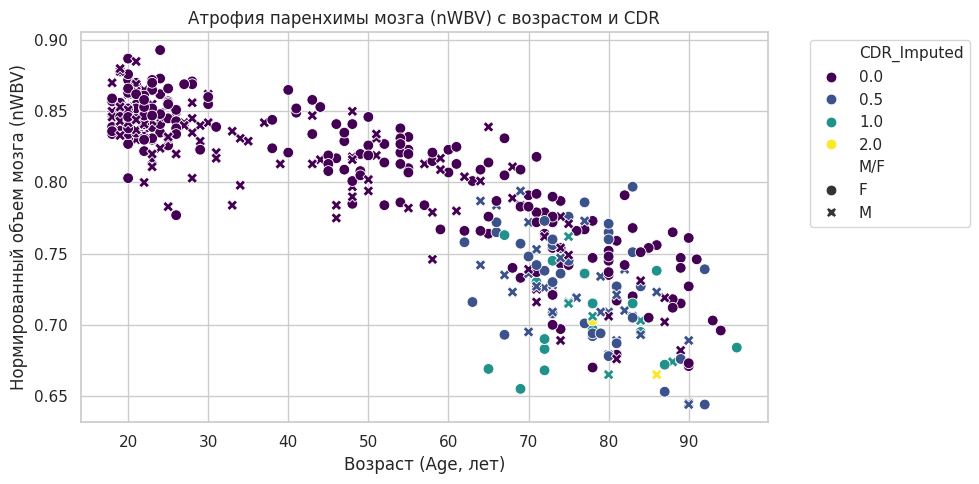

In [37]:
# Падение доли паренхимы мозга (nWBV) с возрастом
plt.figure(figsize=(10, 5))
sns.scatterplot(data=df_clean, x='Age', y='nWBV', hue='CDR_Imputed', style='M/F', palette='viridis', s=60)
plt.title('Атрофия паренхимы мозга (nWBV) с возрастом и CDR')
plt.xlabel('Возраст (Age, лет)')
plt.ylabel('Нормированный объем мозга (nWBV)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

### 12. Оценка масштабирования различных типов признаков FreeSurfer с `eTIV`

Прежде чем применять нормировку ко всем колонкам подряд, необходимо  доказать на наших данных, какие именно группы признаков FreeSurfer зависят от `eTIV`, а какие инвариантны к размеру головы.

* Объемы (`aseg_regional_vol_cols`, `aparc_vol_cols`) и площади поверхности (`aparc_area_cols`) должны показывать сильную положительную корреляцию с `eTIV`.
* Толщина коры (`aparc_thick_avg_cols`) практически не зависит от объема черепа. Если мы ошибочно разделим толщину коры на `eTIV`, мы искусственно создадим ложную отрицательную корреляцию и испортим признаковое пространство.

In [38]:
# Массовый скрининг корреляции морфометрических категорий с eTIV
# (на здоровой когорте df_healthy_brain_age)

print("=" * 65)
print("ПРОВЕРКА ЗАВИСИМОСТИ ПРИЗНАКОВ FREESURFER ОТ eTIV")
print("=" * 65)

# Формируем глобальный список всех признаков, подлежащих проверке
feature_groups_to_test = {
    '1. Подкорковые объемы (aseg)': aseg_regional_vol_cols,
    '2. Объемы коры (aparc GrayVol)': aparc_vol_cols,
    '3. Площадь поверхности коры (aparc SurfArea)': aparc_area_cols,
    '4. Средняя толщина коры (aparc ThickAvg)': aparc_thick_avg_cols,
    '5. Индексы кривизны/складчатости (aparc Curv)': aparc_curv_cols
}

etiv_scaling_records = []
for group_name, cols_list in feature_groups_to_test.items():
    for col in cols_list:
        if col in df_healthy_brain_age.columns:
            r_val, p_val = stats.pearsonr(df_healthy_brain_age['eTIV'], df_healthy_brain_age[col])
            rho_val, _ = stats.spearmanr(df_healthy_brain_age['eTIV'], df_healthy_brain_age[col])
            etiv_scaling_records.append({
                'Feature': col,
                'Group': group_name,
                'Pearson_r_eTIV': r_val,
                'Abs_r_eTIV': abs(r_val),
                'Spearman_rho_eTIV': rho_val,
                'p_value': p_val
            })

df_etiv_scaling = pd.DataFrame(etiv_scaling_records)
_, df_etiv_scaling['p_fdr'], _, _ = multipletests(df_etiv_scaling['p_value'], method='fdr_bh')

# Сводная статистика по группам признаков
scaling_summary = df_etiv_scaling.groupby('Group').agg(
    Features_Count=('Feature', 'count'),
    Mean_Pearson_r=('Pearson_r_eTIV', 'mean'),
    Median_Pearson_r=('Pearson_r_eTIV', 'median'),
    Max_Pearson_r=('Pearson_r_eTIV', 'max'),
    Pct_Significant_FDR05=('p_fdr', lambda x: round((x < 0.05).mean() * 100, 1))
).reset_index()

display(scaling_summary)

ПРОВЕРКА ЗАВИСИМОСТИ ПРИЗНАКОВ FREESURFER ОТ eTIV


,Group,Features_Count,Mean_Pearson_r,Median_Pearson_r,Max_Pearson_r,Pct_Significant_FDR05
0,1. Подкорковые объемы (aseg),41,0.39,0.43,0.79,90.20
1,2. Объемы коры (aparc GrayVol),66,0.52,0.53,0.70,100.00
2,3. Площадь поверхности коры (aparc SurfArea),68,0.58,0.60,0.86,100.00
3,4. Средняя толщина коры (aparc ThickAvg),66,0.07,0.08,0.25,36.40
4,5. Индексы кривизны/складчатости (aparc Curv),66,-0.07,-0.07,0.20,33.30


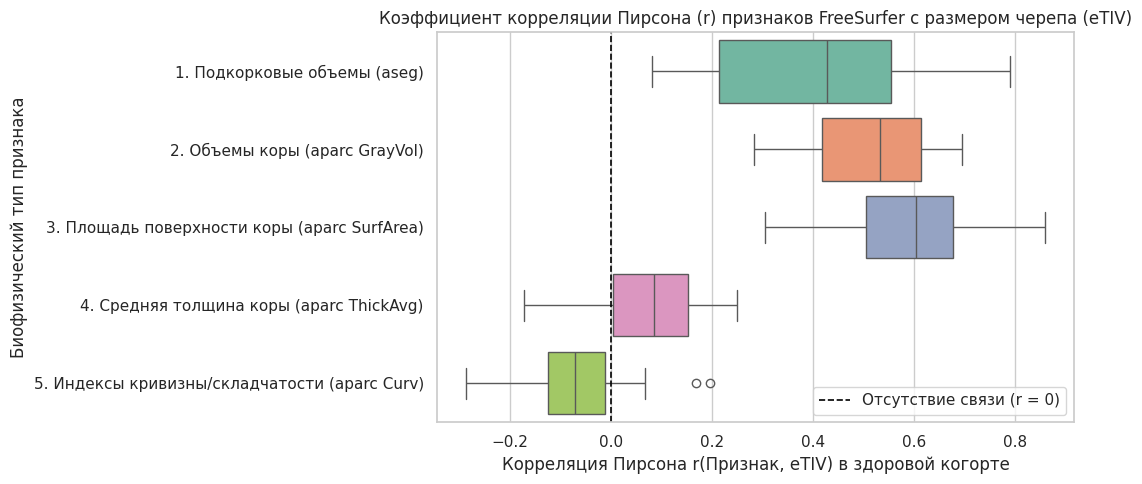

In [39]:
# Визуализация распределения корреляций с eTIV по категориям признаков
plt.figure(figsize=(11, 5))
sns.boxplot(data=df_etiv_scaling, x='Pearson_r_eTIV', y='Group', hue='Group', palette='Set2', showfliers=True)
plt.axvline(0, color='black', linestyle='--', linewidth=1.2, label='Отсутствие связи (r = 0)')
plt.title('Коэффициент корреляции Пирсона (r) признаков FreeSurfer с размером черепа (eTIV)')
plt.xlabel('Корреляция Пирсона r(Признак, eTIV) в здоровой когорте')
plt.ylabel('Биофизический тип признака')
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 13. Реализация пропорциональный нормировки на eTIV

$$V_{\text{prop}} = \frac{V_{\text{raw}}}{\text{eTIV}_{\text{mm}^3}} \times 100\%$$


In [40]:
# Построение датафрейма с нормированными признаками
#    df_norm_prop (Пропорциональная нормировка V / eTIV)

# Фиксируем глобальный список колонок, которые ТРЕБУЮТ нормировки на eTIV:
# Это региональные объемы aseg, объемы серого вещества коры aparc, площади коры aparc,
# а также глобальные тканевые объемы (кроме самого ICV/eTIV и воксельных счетчиков)
aseg_global_to_norm = [c for c in aseg_global_cols if not any(k in c for k in ['ICV', 'IntraCranial', 'NVox'])]
cols_to_normalize = list(dict.fromkeys(aseg_global_to_norm + aseg_regional_vol_cols + aparc_vol_cols + aparc_area_cols))
cols_to_normalize = [c for c in cols_to_normalize if c in df_clean.columns]

# Колонки морфометрии, которые НЕ требуют нормировки на eTIV (толщины коры и кривизна)
cols_unscaled_morph = list(dict.fromkeys(aparc_thick_avg_cols + aparc_thick_std_cols + aparc_curv_cols))
cols_unscaled_morph = [c for c in cols_unscaled_morph if c in df_clean.columns]

print("=" * 60)
print(f"ВЫПОЛНЕНИЕ НОРМИРОВКИ НА eTIV")
print("=" * 60)

print(f"Признаков, подлежащих нормировке (объемы и площади): {len(cols_to_normalize)}")
print(f"Признаков, оставляемых в исходной шкале (толщины и кривизна): {len(cols_unscaled_morph)}")

# Создаем копию df_clean
df_norm_prop = df_clean.copy()

# Приводим eTIV к мм³, если он записан в см³ (для физической интерпретируемости долей в %)
# Проверяем медиану eTIV: если около 1500, то умножаем на 1000 для перевода в мм³
etiv_scale_factor = 1000.0 if df_clean['eTIV'].median() < 10000 else 1.0
etiv_mm3_clean = df_clean['eTIV'] * etiv_scale_factor

# Пропорциональная нормировка (в % от eTIV_mm3)
for col in cols_to_normalize:
    df_norm_prop[col] = (df_clean[col] / etiv_mm3_clean) * 100.0


ВЫПОЛНЕНИЕ НОРМИРОВКИ НА eTIV
Признаков, подлежащих нормировке (объемы и площади): 185
Признаков, оставляемых в исходной шкале (толщины и кривизна): 198


### 14. Пример нормировки на примере Гиппокампа (Ключевого биомаркера болезни Альцгеймера)

Гиппокамп (Left-Hippocampus / Right-Hippocampus) — главная структура-мишень как при старении, так и при болезни Альцгеймера. Визуализация гиппокампа до и после нормировки показывает физический смысл нормировки.

In [42]:
# Визуализация эффекта нормировки на примере объема Гиппокампа
idx_healthy = df_healthy_brain_age.index
hippo_candidates = [c for c in aseg_regional_vol_cols if 'Hippocampus' in c]
hippo_col = hippo_candidates[0] if hippo_candidates else cols_to_normalize[0]

print("=" * 60)
print(f"РАЗБОР БИОМАРКЕРА: {hippo_col}")
print("=" * 60)

# Сравнение половых различий в здоровой группе до и после нормировки
for label, d_frame in [('Raw (мм³)', df_clean), ('Proportion (% от eTIV)', df_norm_prop)]:
    sub_h = d_frame.loc[idx_healthy]
    m_vals = sub_h.loc[sub_h['M/F'] == 'M', hippo_col]
    f_vals = sub_h.loc[sub_h['M/F'] == 'F', hippo_col]
    t_sex, p_sex = stats.ttest_ind(m_vals, f_vals, equal_var=False)
    r_etiv, _ = stats.pearsonr(sub_h['eTIV'], sub_h[hippo_col])
    r_age, _ = stats.pearsonr(sub_h['Age'], sub_h[hippo_col])
    print(f"  • {label:<24} | r(eTIV) = {r_etiv:+.4f} | Различие по полу t(M vs F) = {t_sex:+.2f} (p={p_sex:.3f}) | Сигнал старения r(Age) = {r_age:+.4f}")


РАЗБОР БИОМАРКЕРА: aseg_Left-Hippocampus_Volume_mm3
  • Raw (мм³)                | r(eTIV) = +0.4559 | Различие по полу t(M vs F) = +5.79 (p=0.000) | Сигнал старения r(Age) = -0.6497
  • Proportion (% от eTIV)   | r(eTIV) = -0.3178 | Различие по полу t(M vs F) = -2.53 (p=0.012) | Сигнал старения r(Age) = -0.5176


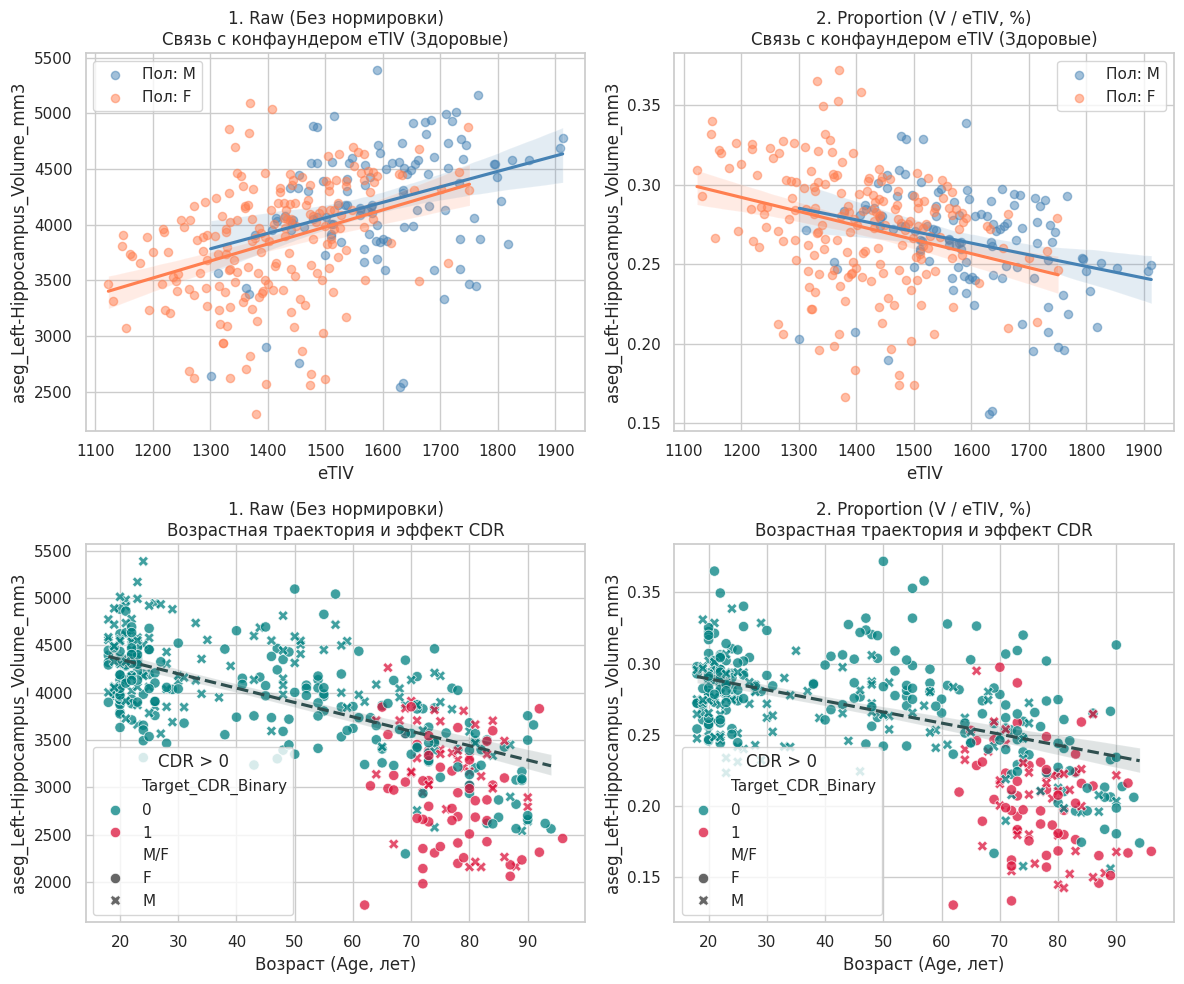

In [43]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()

datasets_plot = [
    ('1. Raw (Без нормировки)', df_clean),
    ('2. Proportion (V / eTIV, %)', df_norm_prop)
]

for col_idx, (title_prefix, d_frame) in enumerate(datasets_plot):
    # Верхний ряд: Зависимость от eTIV по полу в здоровой когорте
    sub_healthy = d_frame.loc[idx_healthy]
    for sex_val, color in [('M', 'steelblue'), ('F', 'coral')]:
        s_data = sub_healthy[sub_healthy['M/F'] == sex_val]
        sns.regplot(data=s_data, x='eTIV', y=hippo_col, ax=axes[col_idx], color=color,
                    label=f"Пол: {sex_val}", scatter_kws={'alpha': 0.5, 's': 35})
    axes[col_idx].set_title(f"{title_prefix}\nСвязь с конфаундером eTIV (Здоровые)")
    axes[col_idx].set_xlabel('eTIV')
    axes[col_idx].set_ylabel(hippo_col)
    axes[col_idx].legend()

    # Нижний ряд: Возрастная траектория и отрыв пациентов с деменцией (CDR > 0)
    sns.scatterplot(data=d_frame, x='Age', y=hippo_col, hue='Target_CDR_Binary', style='M/F',
                    palette={0: 'teal', 1: 'crimson'}, alpha=0.75, s=55, ax=axes[col_idx + 2])
    # Линия тренда нормального старения (по здоровым)
    sns.regplot(data=sub_healthy, x='Age', y=hippo_col, scatter=False, ax=axes[col_idx + 2],
                color='darkslategray', line_kws={'linestyle': '--', 'label': 'Тренд нормы (CDR=0)'})
    axes[col_idx + 2].set_title(f"{title_prefix}\nВозрастная траектория и эффект CDR")
    axes[col_idx + 2].set_xlabel('Возраст (Age, лет)')
    axes[col_idx + 2].set_ylabel(hippo_col)
    axes[col_idx + 2].legend(title='CDR > 0')

plt.tight_layout()
plt.show()


## Результаты EDA по клиническим и демографическим данным, решения и выводы

Набор данных OASIS-1 содержит 425 МРТ-сканов. 12 клинико-демографических признаков, полученных от 405 уникальных испытуемых в возрасте от 18 до 96 лет. Разведочный анализ данных (EDA) выявляет стратификацию выборки по возрасту, неслучайную природу пропусков в клинических шкалах и выраженную коллинеарность морфометрических метрик.

### 1. Аудит схемы данных, дубликатов субъектов и природы пропусков

Первичный аудит структуры показывает, что 425 строк состоят из 405 первичных сканов (`MR1`) и 20 повторных сканов (`MR2`), выполненных для проверки воспроизводимости морфометрии у здоровых молодых добровольцев с интервалом от 1 до 89 дней.

Ключевые выводы по качеству данных и пропускам:

* Нулевая дисперсия признака `Hand`  
Все 425 записей имеют значение `'R'` (правши) — это жесткий критерий включения в протокол OASIS-1 для исключения латерализационных искажений мозга. Признак не несет предсказательной силы и подлежит удалению.
* Утечка данных через повторные сканы (`MR2`)  
Если оставить 20 записей с `Delay != NaN` (`_MR2`) в наборе при случайном `train_test_split`, один и тот же субъект попадет в обучение и тест. Для кросс-секционного моделирования необходимо отфильтровать только `MR1` ($N = 405$).
* Пропуски в клинических признаках (`CDR`, `MMSE`, `Educ`, `SES`)  
У 201 испытуемого (46.1%) синхронно отсутствуют значения `CDR`, `MMSE` и `Educ`. Средний возраст этой группы составляет 26.82 года (медиана 23 года, диапазон 18–58 лет), тогда как у 235 обследованных пациентов средний возраст равен 72.34года (медиана 73 года, диапазон 33–96 лет). Молодая когорта набиралась как заведомо здоровая группа контроля без проведения скрининга на деменцию. Импутировать `MMSE` или `Educ` медианой по всей выборке нельзя поскольку это припишет молодым испытуемым когнитивный профиль пожилых. Для задач бинарной классификации в когорте здорового контроля можно кодировать молодым субъектам `CDR = 0.0`, но классификацию болезни Альцгеймера нужно проводить строго внутри возрастной когорты ($\text{Age} \ge 60$ лет).

### 2. Распределения и дисбалансы

* Бимодальность возраста
В OASIS-1 распределение возраста резко двугорбое: пик около 20–25 лет (студенты университета, у всех CDR = NaN) и вторая категория от 36 до 96 лет (где измерялся CDR).
    - Решение для анализа старения (Aging): используем всех первичных субъектов (df_mr1) с CDR == 0 или CDR.isna(), исключив субьектов с CDR > 0.

    - Решение для анализа болезни Альцгеймера: используем только старшую когорту (df_elderly_cdr, возраст $\ge 60$ лет, где CDR явно измерен), иначе сравнение CDR > 0 против всех здоровых превратится в сравнение 75-летних пожилых с 20-летними студентами.

* Дисбаланс классов в CDR:
В старшей группе распределение CDR сильно скошено:
    - CDR = 0.0 (здоровая старость): 133 человек;
    - CDR = 0.5 (очень легкая деменция / MCI): 68 человек;
    - CDR = 1.0 (легкая деменция): 23 человек;
    - CDR = 2.0 (умеренная деменция): всего 2 человека.
    - Решение: из-за того, что в классе CDR = 2.0 всего 2 наблюдения, для статистических тестов и регрессий, сделаем бинарную классификацию: CDR = 0 против CDR > 0.


### 3. Морфометрический профиль, конфаундеры (Age, Sex) и аномалии данных

* Траектория атрофии участков мозга (`nWBV`)  
Показатель `nWBV` (Normalized Whole Brain Volume — доля объема вещества мозга относительно интракраниального объема) показывает отрицательную линейную корреляцию с возрастом.
* Половой диморфизм `eTIV` и его независимость от атрофии  
 Оценка интракраниального объема (`eTIV`) статистически значимо выше у мужчин (1592.4см³, медиана 1581.5), чем у женщин (1412.7см³, медиана 1407.5
* Коллинеарность `eTIV` и `ASF` + обнаружение единичного выброса  
Коэффициент масштабирования атласа (`ASF`) вычисляется по формуле $\text{ASF} = \frac{1755}{\text{eTIV}}$. Совместное использование `eTIV` и `ASF` в линейных моделях вызовет мультиколлинеарность (`ASF` следует исключить). Кроме того, на графике в правом верхнем углу виден явный технический выброс точка с `eTIV = 1748` и `ASF = 1.442`. Эту запись необходимо проверить при слиянии с таблицей `aseg.stats` (сопоставив с `aseg_ICV`).

### 4. Взаимосвязь когнитивных и социально-демографических факторов

* `MMSE` и `CDR`  
 Между баллом `MMSE` и `CDR` наблюдается сильная отрицательная корреляция. Если цель модели предсказание `CDR` исключительно по МРТ-морфометрии, `MMSE` необходимо исключить из матрицы признаков во избежание утечки (target leakage).
* Когнитивный резерв (`Educ` и `SES`)  
 Уровень образования (`Educ`, от 1 до 5) и социально-экономический статус (`SES`, где 1 — высший, а 5 — низший класс по Холлингсхеду) сильно обратно коррелируют между собой. Более высокий уровень образования ассоциирован с более высоким баллом `MMSE` и меньшей частотой деменции, что отражает гипотезу когнитивного резерва.